# Model Building and Evaluation

## 1. Introduction

In this phase, we build, train, and evaluate several supervised machine
learning classification models to predict hotel booking cancellations.

The target variable is `booking status`, which contains two classes:

-   `Canceled`
-   `Not_Canceled`

The main objective is to identify bookings that are likely to be
canceled. Therefore, model evaluation focuses not only on overall
accuracy but also on the Precision, Recall, and F1-score of the
`Canceled` class.


In [2]:
import sys
from pathlib import Path
import pandas as pd
import numpy as np
from sklearn.linear_model import LogisticRegression

PROJECT_ROOT = Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT))

from src.data_loader import load_data
from src.preprocessing import prepare_data
from src.evaluate import evaluate_model




## 2. Loading the Prepared Data

We load the original dataset and separate the input features from the
target variable.

The following columns are excluded:

-   `Booking_ID`: an identifier that does not provide useful predictive
    information.
-   `date of reservation`: excluded because its meaning and availability
    at booking-registration time were not sufficiently documented.
-   `booking status`: the target variable.

The remaining dataset contains 14 input features: 11 numerical features
and 3 categorical features.

We then use the reusable `prepare_data()` function from
`src/preprocessing.py` to split and preprocess the data.


In [ ]:
# Load dataset
df = load_data()

# Separate features and target
X = df.drop(columns=[
    "Booking_ID",
    "date of reservation",
    "booking status"
])

y = df["booking status"]

# Split and preprocess data
data = prepare_data(X, y)

# Retrieve prepared datasets
X_train = data["X_train_processed"]
X_test = data["X_test_processed"]

y_train = data["y_train_encoded"]
y_test = data["y_test_encoded"]

# Retrieve original target labels
y_train_original = data["y_train"]
y_test_original = data["y_test"]

# Retrieve fitted preprocessing objects
encoder = data["encoder"]
scaler = data["scaler"]
target_encoder = data["target_encoder"]

print("Training Data Shape:", X_train.shape)
print("Testing Data Shape:", X_test.shape)

print("Training Target Shape:", y_train.shape)
print("Testing Target Shape:", y_test.shape)

Training Data Shape: (29028, 27)
Testing Data Shape: (7257, 27)
Training Target Shape: (29028,)
Testing Target Shape: (7257,)



The resulting dataset contains:

  Dataset      Number of Records   Number of Features
  ---------- ------------------- --------------------
  Training                29,028                   27
  Testing                  7,257                   27

The target variable is also encoded as follows:

  Original Class     Encoded Value
  ---------------- ---------------
  Canceled                       0
  Not_Canceled                   1

The original target labels are retained for interpretation and
reporting.



## 3. Evaluation Strategy and Metrics

We evaluate each model using the training and testing datasets.

The following metrics are used:

-   **Accuracy:** the proportion of all predictions that are correct.
-   **Precision:** the proportion of predicted positive cases that are
    actually positive.
-   **Recall:** the proportion of actual positive cases correctly
    identified.
-   **F1-score:** the harmonic mean of Precision and Recall.

In this project, `Canceled` is encoded as class `0`. Since cancellation
detection is our main objective, we specifically calculate Precision,
Recall, and F1-score using `pos_label=0`.

This distinction is important because scikit-learn classification
metrics use class `1` as the positive class by default for binary
classification.

We also inspect the classification report to evaluate both classes
separately.


---
----

## 4. Logistic Regression

Logistic Regression is a supervised learning algorithm commonly used for
binary classification.

It estimates the probability that an observation belongs to a particular
class and uses a decision threshold to produce a class prediction.

We train the model with `max_iter=1000` to allow the optimization
process enough iterations to converge.

In [4]:
# Initialize the model
logistic_model = LogisticRegression(max_iter=1000 , random_state=42)

# Train the model
logistic_model.fit(X_train, y_train)

print("Logistic Regression model trained successfully!")


Logistic Regression model trained successfully!


In [5]:
# Generate predictions
y_pred = logistic_model.predict(X_test)
y_train_pred = logistic_model.predict(X_train)

print("Predictions Test Shape:", y_pred.shape)
print("\nFirst 10 Predictions:")
print(y_pred[:10])

print("*" * 50)

print("Predictions Train Shape:", y_train_pred.shape)
print("\nFirst 10 Predictions:")
print(y_train_pred[:10])

Predictions Test Shape: (7257,)

First 10 Predictions:
[1 0 1 0 1 0 1 1 0 1]
**************************************************
Predictions Train Shape: (29028,)

First 10 Predictions:
[0 1 0 1 1 1 1 1 1 1]


Evaluation Results: Logistic Regression
--------------------------------------------------
Test Accuracy:  0.8058
Test Precision: 0.8286
Test Recall:    0.8967
Test F1 Score:  0.8613
Train Accuracy:  0.7981
Train Precision: 0.8237
Train Recall:    0.8902
Train F1 Score:  0.8557

Classification Report:
              precision    recall  f1-score   support

    Canceled       0.75      0.62      0.68      2378
Not_Canceled       0.83      0.90      0.86      4879

    accuracy                           0.81      7257
   macro avg       0.79      0.76      0.77      7257
weighted avg       0.80      0.81      0.80      7257


Train Classification Report:
              precision    recall  f1-score   support

    Canceled       0.73      0.61      0.66      9511
Not_Canceled       0.82      0.89      0.86     19517

    accuracy                           0.80     29028
   macro avg       0.78      0.75      0.76     29028
weighted avg       0.79      0.80      0.79     29028



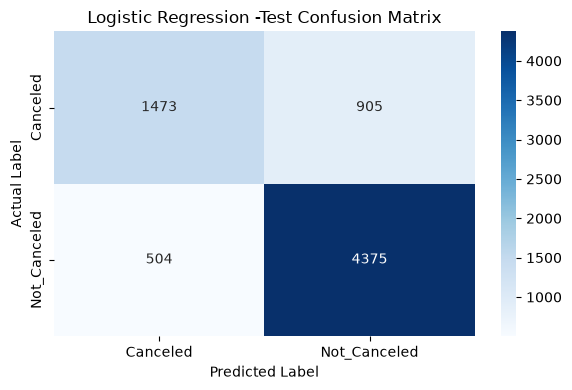

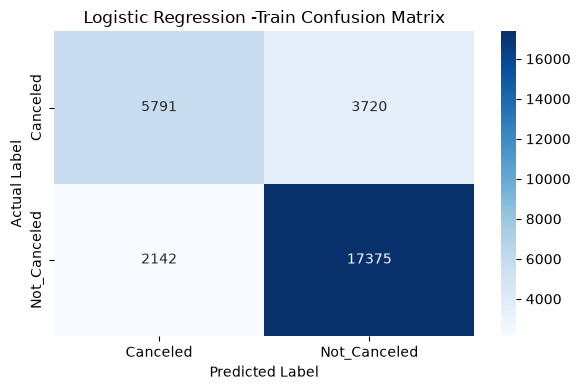

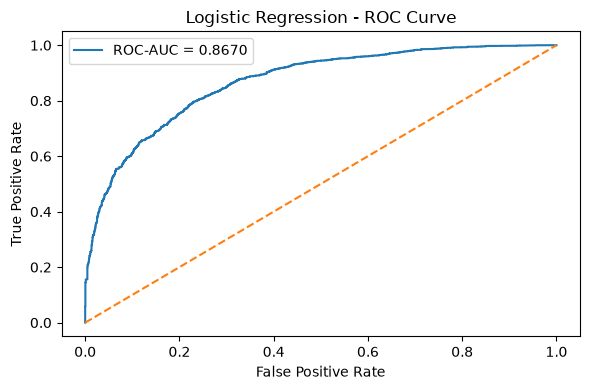

ROC-AUC:  0.8670


In [6]:
logistic_results = evaluate_model(
    model=logistic_model,
    X_train=X_train,
    y_train=y_train,
    X_test=X_test,
    y_test=y_test,
    model_name="Logistic Regression"
)


### Test Results

  Metric                          Score
  ---------------------------- --------
  Accuracy                       80.58%
  Precision (`Not_Canceled`)     82.86%
  Recall (`Not_Canceled`)        89.67%
  F1-score (`Not_Canceled`)      86.13%
  Precision (`Canceled`)            75%
  Recall (`Canceled`)               62%
  F1-score (`Canceled`)             68%

The model performs reasonably well at identifying non-canceled bookings,
but it misses a considerable proportion of canceled bookings. It is used
as an initial model for comparison.

----
----

## 5. Decision Tree Classifier

A Decision Tree is a supervised learning algorithm used for
classification and regression.

It makes predictions by recursively splitting the dataset into smaller
subsets based on feature values. Each internal node represents a
decision rule, each branch represents an outcome, and each leaf node
represents a prediction.

In [7]:

from sklearn.tree import DecisionTreeClassifier

# Initialize the model
decision_tree_model = DecisionTreeClassifier(
    random_state=42
)
# Train the model
decision_tree_model.fit(X_train, y_train)

print("Decision Tree model trained successfully!")

Decision Tree model trained successfully!


Evaluation Results: Decision Tree
--------------------------------------------------
Test Accuracy:  0.8626
Test Precision: 0.9015
Test Recall:    0.8932
Test F1 Score:  0.8974
Train Accuracy:  0.9920
Train Precision: 0.9946
Train Recall:    0.9936
Train F1 Score:  0.9941

Classification Report:
              precision    recall  f1-score   support

    Canceled       0.78      0.80      0.79      2378
Not_Canceled       0.90      0.89      0.90      4879

    accuracy                           0.86      7257
   macro avg       0.84      0.85      0.84      7257
weighted avg       0.86      0.86      0.86      7257


Train Classification Report:
              precision    recall  f1-score   support

    Canceled       0.99      0.99      0.99      9511
Not_Canceled       0.99      0.99      0.99     19517

    accuracy                           0.99     29028
   macro avg       0.99      0.99      0.99     29028
weighted avg       0.99      0.99      0.99     29028



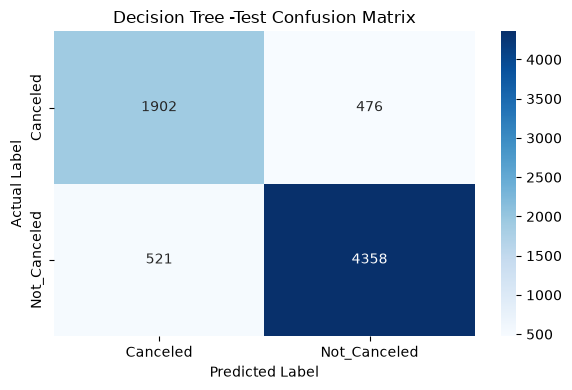

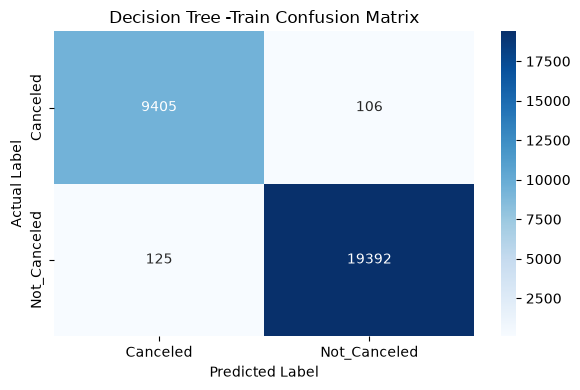

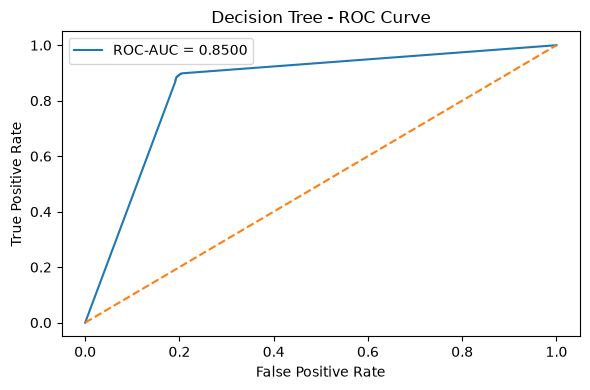

ROC-AUC:  0.8500


In [9]:
decision_tree_results = evaluate_model(
    model=decision_tree_model,
    X_train=X_train,
    y_train=y_train,
    X_test=X_test,
    y_test=y_test,
    model_name="Decision Tree"
)



### Evaluation Results

  Metric                       Test    Train
  ------------------------ -------- --------
  Accuracy                   86.26%   99.20%
  Precision (`Canceled`)        78%      ---
  Recall (`Canceled`)           80%      ---
  F1-score (`Canceled`)         79%      ---

The training accuracy is considerably higher than the testing accuracy.
This large gap indicates overfitting: the model learns the training data
very closely but does not generalize as well to unseen data.

----
----

## 6. Random Forest Classifier

Random Forest is an ensemble learning algorithm that combines multiple
Decision Trees.

Each tree is trained using a sample of the training data and considers a
subset of features when making splits. For classification, the trees'
predictions are combined through majority voting.

Random Forest can improve generalization compared with a single Decision
Tree.


In [10]:
from sklearn.ensemble import RandomForestClassifier

# Initialize the model
random_forest_model = RandomForestClassifier(
    random_state=42
)

# Train the model
random_forest_model.fit(X_train, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


Evaluation Results: Random Forest
--------------------------------------------------
Test Accuracy:  0.8910
Test Precision: 0.9065
Test Recall:    0.9342
Test F1 Score:  0.9202
Train Accuracy:  0.9920
Train Precision: 0.9919
Train Recall:    0.9962
Train F1 Score:  0.9941

Classification Report:
              precision    recall  f1-score   support

    Canceled       0.86      0.80      0.83      2378
Not_Canceled       0.91      0.93      0.92      4879

    accuracy                           0.89      7257
   macro avg       0.88      0.87      0.87      7257
weighted avg       0.89      0.89      0.89      7257


Train Classification Report:
              precision    recall  f1-score   support

    Canceled       0.99      0.98      0.99      9511
Not_Canceled       0.99      1.00      0.99     19517

    accuracy                           0.99     29028
   macro avg       0.99      0.99      0.99     29028
weighted avg       0.99      0.99      0.99     29028



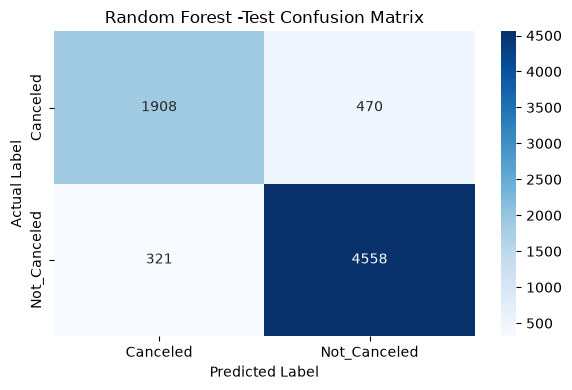

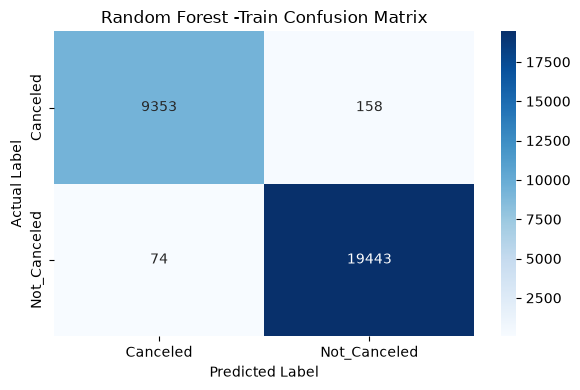

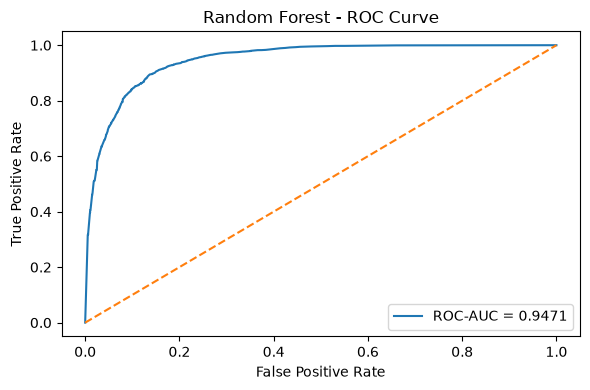

ROC-AUC:  0.9471


In [12]:
random_forest_results = evaluate_model(
    model=random_forest_model,
    X_train=X_train,
    y_train=y_train,
    X_test=X_test,
    y_test=y_test,
    model_name="Random Forest"
)


### Evaluation Results

  Metric                       Test    Train
  ------------------------ -------- --------
  Accuracy                   89.10%   99.20%
  Precision (`Canceled`)        86%      ---
  Recall (`Canceled`)           80%      ---
  F1-score (`Canceled`)         83%      ---

The initial Random Forest achieves the strongest overall test
performance among the first group of models. However, the difference
between training and testing accuracy indicates overfitting, so we
investigate whether its hyperparameters can be improved.

----
----

## 7. Gradient Boosting Classifier

Gradient Boosting is an ensemble learning algorithm that builds a
sequence of weak learners, usually Decision Trees.

Unlike Random Forest, which trains trees independently, Gradient
Boosting builds trees sequentially. Each new tree attempts to correct
errors made by the existing ensemble by minimizing a loss function.


In [13]:
from sklearn.ensemble import GradientBoostingClassifier

# Initialize the model
gradient_boosting_model = GradientBoostingClassifier(
    random_state=42
)

# Train the model
gradient_boosting_model.fit(X_train, y_train)

print("Gradient Boosting model trained successfully!")

Gradient Boosting model trained successfully!


Evaluation Results: Gradient Boosting
--------------------------------------------------
Test Accuracy:  0.8532
Test Precision: 0.8639
Test Recall:    0.9279
Test F1 Score:  0.8948
Train Accuracy:  0.8504
Train Precision: 0.8604
Train Recall:    0.9281
Train F1 Score:  0.8929

Classification Report:
              precision    recall  f1-score   support

    Canceled       0.83      0.70      0.76      2378
Not_Canceled       0.86      0.93      0.89      4879

    accuracy                           0.85      7257
   macro avg       0.84      0.81      0.83      7257
weighted avg       0.85      0.85      0.85      7257


Train Classification Report:
              precision    recall  f1-score   support

    Canceled       0.82      0.69      0.75      9511
Not_Canceled       0.86      0.93      0.89     19517

    accuracy                           0.85     29028
   macro avg       0.84      0.81      0.82     29028
weighted avg       0.85      0.85      0.85     29028



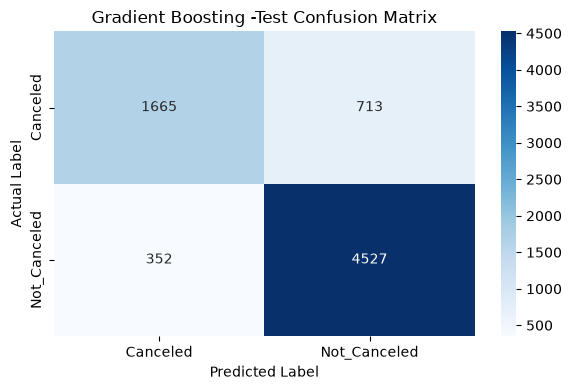

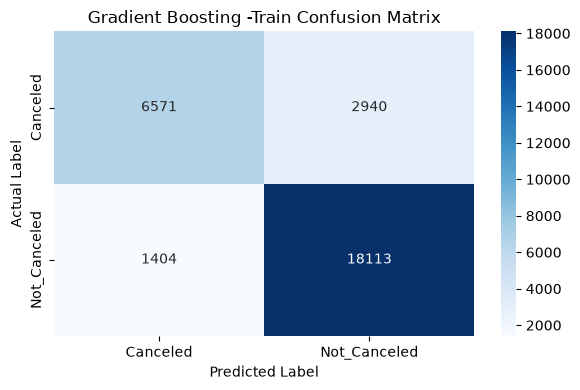

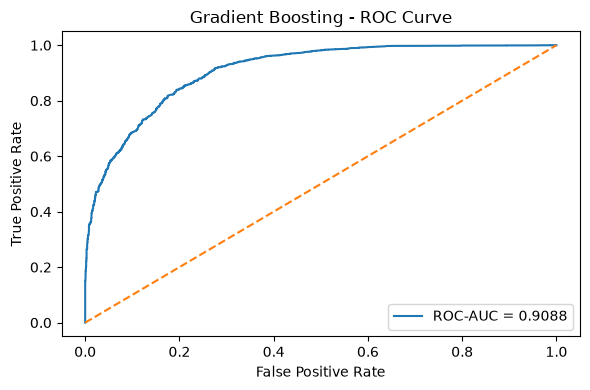

ROC-AUC:  0.9088


In [15]:
gradient_boosting_results = evaluate_model(
    model=gradient_boosting_model,
    X_train=X_train,
    y_train=y_train,
    X_test=X_test,
    y_test=y_test,
    model_name="Gradient Boosting"
)


### Evaluation Results

  Metric                       Test    Train
  ------------------------ -------- --------
  Accuracy                   85.32%   85.04%
  Precision (`Canceled`)        83%      ---
  Recall (`Canceled`)           70%      ---
  F1-score (`Canceled`)         76%      ---

The training and testing accuracy are close, suggesting limited
overfitting. However, the model detects fewer canceled bookings than
Random Forest and Decision Tree.

----
----

## 8. Support Vector Classifier (SVC)

Support Vector Classifier is a supervised learning algorithm that finds
a decision boundary, called a hyperplane, to separate classes.

It aims to maximize the margin between the decision boundary and the
closest observations, known as Support Vectors. SVC can also model
non-linear decision boundaries using kernel functions.

The model is trained using the default RBF kernel.

In [16]:
from sklearn.svm import SVC

# Initialize the model
svc_model = SVC(
    random_state=42
)

# Train the model
svc_model.fit(X_train, y_train)

print("SVC model trained successfully!")

SVC model trained successfully!


Evaluation Results: SVC
--------------------------------------------------
Test Accuracy:  0.8364
Test Precision: 0.8396
Test Recall:    0.9354
Test F1 Score:  0.8849
Train Accuracy:  0.8343
Train Precision: 0.8387
Train Recall:    0.9330
Train F1 Score:  0.8833

Classification Report:
              precision    recall  f1-score   support

    Canceled       0.83      0.63      0.72      2378
Not_Canceled       0.84      0.94      0.88      4879

    accuracy                           0.84      7257
   macro avg       0.83      0.78      0.80      7257
weighted avg       0.84      0.84      0.83      7257


Train Classification Report:
              precision    recall  f1-score   support

    Canceled       0.82      0.63      0.71      9511
Not_Canceled       0.84      0.93      0.88     19517

    accuracy                           0.83     29028
   macro avg       0.83      0.78      0.80     29028
weighted avg       0.83      0.83      0.83     29028



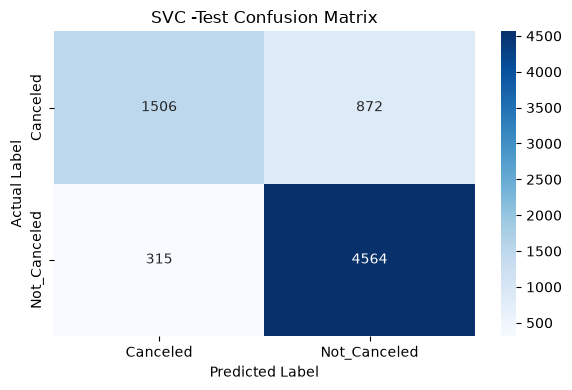

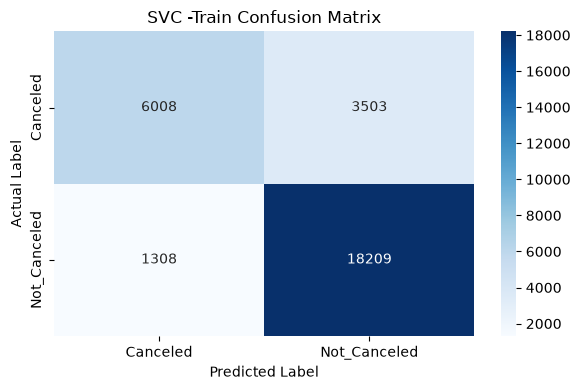

In [18]:
svc_results = evaluate_model(
    model=svc_model,
    X_train=X_train,
    y_train=y_train,
    X_test=X_test,
    y_test=y_test,
    model_name="SVC"
)


### Evaluation Results

  Metric                       Test    Train
  ------------------------ -------- --------
  Accuracy                   83.64%   83.43%
  Precision (`Canceled`)        83%      ---
  Recall (`Canceled`)           63%      ---
  F1-score (`Canceled`)         72%      ---

The small difference between training and testing accuracy suggests
stable generalization. However, its cancellation Recall and F1-score are
lower than those of Random Forest.


In [19]:
model_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest",
        "Gradient Boosting",
        "SVC"
    ],

    "Test Accuracy": [
        0.8058,
        0.8626,
        0.8910,
        0.8532,
        0.8364
    ],

    "Train Accuracy": [
        0.7981,
        0.9920,
        0.9920,
        0.8504,
        0.8343
    ],

    "Canceled Precision": [
        0.75,
        0.78,
        0.86,
        0.83,
        0.83
    ],

    "Canceled Recall": [
        0.62,
        0.80,
        0.80,
        0.70,
        0.63
    ],

    "Canceled F1 Score": [
        0.68,
        0.79,
        0.83,
        0.76,
        0.72
    ]
})

model_comparison["Accuracy Gap"] = (
    model_comparison["Train Accuracy"] -
    model_comparison["Test Accuracy"]
)

model_comparison = model_comparison.sort_values(
    by="Test Accuracy",
    ascending=False
).reset_index(drop=True)

model_comparison

,Model,Test Accuracy,Train Accuracy,Canceled Precision,Canceled Recall,Canceled F1 Score,Accuracy Gap
0,Random Forest,0.8910,0.9920,0.86,0.80,0.83,0.1010
1,Decision Tree,0.8626,0.9920,0.78,0.80,0.79,0.1294
2,Gradient Boosting,0.8532,0.8504,0.83,0.70,0.76,-0.0028
3,SVC,0.8364,0.8343,0.83,0.63,0.72,-0.0021
4,Logistic Regression,0.8058,0.7981,0.75,0.62,0.68,-0.0077



## 9. Initial Model Performance Comparison

After training and evaluating the five classification models, we compare their performance using the same testing dataset.

The comparison focuses on overall Accuracy and the ability to identify canceled bookings through Canceled Precision, Recall, and F1-score.

### Model Performance Comparison

| Model | Test Accuracy | Train Accuracy | Canceled Precision | Canceled Recall | Canceled F1 |
|---|---:|---:|---:|---:|---:|
| Random Forest | **89.10%** | 99.20% | **86%** | 80% | **83%** |
| Decision Tree | 86.26% | 99.20% | 78% | **80%** | 79% |
| Gradient Boosting | 85.32% | 85.04% | 83% | 70% | 76% |
| SVC | 83.64% | 83.43% | 83% | 63% | 72% |
| Logistic Regression | 80.58% | 79.81% | 75% | 62% | 68% |

### Performance Analysis

- **Random Forest** achieves the highest Test Accuracy (89.10%) and Canceled F1-score (83%), making it the strongest overall candidate.
- **Decision Tree** achieves the same Canceled Recall (80%) as Random Forest, but has lower Precision and F1-score, along with a larger train-test performance gap.
- **Gradient Boosting** and **SVC** show relatively small differences between training and testing Accuracy, indicating better generalization. However, their ability to identify canceled bookings is lower.
- **Logistic Regression** provides the lowest performance among the evaluated models, particularly in identifying canceled bookings.

### Initial Model Selection

Based on these results, Random Forest is selected as the leading candidate for further evaluation.

However, its high training Accuracy (99.20%) compared with its testing Accuracy (89.10%) indicates potential overfitting.

Therefore, we proceed with Cross-Validation and Hyperparameter Tuning to investigate whether its generalization performance can be improved.




## 10. Cross-Validation

A single train-test split may not fully represent how a model performs
on different subsets of the training data. To obtain a more reliable
estimate, we use 5-Fold Stratified Cross-Validation.

Stratification preserves the target class distribution across folds.

During the initial cross-validation experiment, preprocessing had been
fitted before the folds were created. This allowed information from each
validation fold to influence preprocessing parameters such as scaling
statistics and discovered categories.

To avoid this preprocessing leakage, we repeated cross-validation using
the raw training data. For every fold:

1.  The raw training and validation subsets are separated.
2.  The encoder, scaler, and target encoder are fitted using only that
    fold's training subset.
3.  The fitted preprocessing objects transform the corresponding
    validation subset.
4.  A fresh clone of the model is trained and evaluated.

In [20]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import make_scorer, precision_score, recall_score, f1_score

# Define cross-validation strategy
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Define evaluation metrics
scoring = {
    "accuracy": "accuracy",
    "canceled_precision": make_scorer(
        precision_score,
        pos_label=0,
        zero_division=0
    ),
    "canceled_recall": make_scorer(
        recall_score,
        pos_label=0,
        zero_division=0
    ),
    "canceled_f1": make_scorer(
        f1_score,
        pos_label=0,
        zero_division=0
    )
}

# Define models
models = {
    "Logistic Regression": logistic_model,
    "Decision Tree": decision_tree_model,
    "Random Forest": random_forest_model,
    "Gradient Boosting": gradient_boosting_model,
    "SVC": svc_model
}

print("Cross-validation setup completed!")

Cross-validation setup completed!


In [21]:
cv_results = {}

for model_name, model in models.items():

    print(f"Evaluating {model_name}...")

    scores = cross_validate(
        estimator=model,
        X=X_train,
        y=y_train,
        cv=cv,
        scoring=scoring,
        return_train_score=True
    )

    cv_results[model_name] = scores

print("\nCross-validation completed successfully!")

Evaluating Logistic Regression...
Evaluating Decision Tree...
Evaluating Random Forest...
Evaluating Gradient Boosting...
Evaluating SVC...

Cross-validation completed successfully!


In [22]:
cv_summary = []

for model_name, scores in cv_results.items():

    cv_summary.append({
        "Model": model_name,

        "Mean CV Accuracy": scores["test_accuracy"].mean(),
        "Std CV Accuracy": scores["test_accuracy"].std(),

        "Mean Canceled Precision": scores["test_canceled_precision"].mean(),
        "Mean Canceled Recall": scores["test_canceled_recall"].mean(),
        "Mean Canceled F1": scores["test_canceled_f1"].mean(),

        "Mean Train Accuracy": scores["train_accuracy"].mean()
    })

cv_comparison = pd.DataFrame(cv_summary)

cv_comparison = cv_comparison.sort_values(
    by="Mean Canceled F1",
    ascending=False
).reset_index(drop=True)

cv_comparison

,Model,Mean CV Accuracy,Std CV Accuracy,Mean Canceled Precision,Mean Canceled Recall,Mean Canceled F1,Mean Train Accuracy
0,Random Forest,0.881356,0.001388,0.841860,0.785511,0.812688,0.992662
1,Decision Tree,0.848216,0.002534,0.760123,0.784249,0.771992,0.992671
2,Gradient Boosting,0.847630,0.002991,0.819838,0.685837,0.746828,0.850506
3,SVC,0.826857,0.001911,0.808347,0.618231,0.700572,0.832920
4,Logistic Regression,0.798608,0.004575,0.731754,0.608453,0.664372,0.799246


In [23]:
from sklearn.base import clone
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

from src.preprocessing import preprocess_data

# Retrieve raw training data
X_train_raw = data["X_train"]
y_train_raw = data["y_train"]

print("Raw Training Features:", X_train_raw.shape)
print("Raw Training Target:", y_train_raw.shape)

Raw Training Features: (29028, 14)
Raw Training Target: (29028,)


In [24]:
from sklearn.base import clone
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

from src.preprocessing import preprocess_data

# Store cross-validation results
cv_results = {}

for model_name, model in models.items():

    fold_results = {
        "train_accuracy": [],
        "test_accuracy": [],
        "canceled_precision": [],
        "canceled_recall": [],
        "canceled_f1": []
    }

    for train_idx, val_idx in cv.split(X_train_raw, y_train_raw):

        # Split raw data for the current fold
        X_fold_train = X_train_raw.iloc[train_idx]
        X_fold_val = X_train_raw.iloc[val_idx]

        y_fold_train = y_train_raw.iloc[train_idx]
        y_fold_val = y_train_raw.iloc[val_idx]

        # Preprocess using only the current fold's training data
        fold_data = preprocess_data(
            X_fold_train,
            X_fold_val,
            y_fold_train,
            y_fold_val
        )

        X_fold_train_processed = fold_data["X_train_processed"]
        X_fold_val_processed = fold_data["X_test_processed"]

        y_fold_train_encoded = fold_data["y_train_encoded"]
        y_fold_val_encoded = fold_data["y_test_encoded"]

        # Create and train a fresh model
        fold_model = clone(model)

        fold_model.fit(
            X_fold_train_processed,
            y_fold_train_encoded
        )

        # Predictions
        train_predictions = fold_model.predict(X_fold_train_processed)
        val_predictions = fold_model.predict(X_fold_val_processed)

        # Evaluate the model
        fold_results["train_accuracy"].append(
            accuracy_score(y_fold_train_encoded, train_predictions)
        )

        fold_results["test_accuracy"].append(
            accuracy_score(y_fold_val_encoded, val_predictions)
        )

        fold_results["canceled_precision"].append(
            precision_score(
                y_fold_val_encoded,
                val_predictions,
                pos_label=0,
                zero_division=0
            )
        )

        fold_results["canceled_recall"].append(
            recall_score(
                y_fold_val_encoded,
                val_predictions,
                pos_label=0,
                zero_division=0
            )
        )

        fold_results["canceled_f1"].append(
            f1_score(
                y_fold_val_encoded,
                val_predictions,
                pos_label=0,
                zero_division=0
            )
        )

    cv_results[model_name] = fold_results

    print(f"{model_name} - Cross-Validation Completed")

Logistic Regression - Cross-Validation Completed
Decision Tree - Cross-Validation Completed
Random Forest - Cross-Validation Completed
Gradient Boosting - Cross-Validation Completed
SVC - Cross-Validation Completed


In [25]:
cv_summary = []

for model_name, scores in cv_results.items():

    cv_summary.append({
        "Model": model_name,

        "Mean CV Accuracy": np.mean(scores["test_accuracy"]),

        "Std CV Accuracy": np.std(
            scores["test_accuracy"],
            ddof=1
        ),

        "Mean Train Accuracy": np.mean(
            scores["train_accuracy"]
        ),

        "Mean Canceled Precision": np.mean(
            scores["canceled_precision"]
        ),

        "Mean Canceled Recall": np.mean(
            scores["canceled_recall"]
        ),

        "Mean Canceled F1": np.mean(
            scores["canceled_f1"]
        )
    })

cv_comparison = pd.DataFrame(cv_summary)

cv_comparison = cv_comparison.sort_values(
    by="Mean Canceled F1",
    ascending=False
).reset_index(drop=True)

cv_comparison

,Model,Mean CV Accuracy,Std CV Accuracy,Mean Train Accuracy,Mean Canceled Precision,Mean Canceled Recall,Mean Canceled F1
0,Random Forest,0.881184,0.001769,0.992662,0.841542,0.785300,0.812426
1,Decision Tree,0.848319,0.002833,0.992671,0.760567,0.783829,0.772014
2,Gradient Boosting,0.847630,0.003344,0.850506,0.819838,0.685837,0.746828
3,SVC,0.827064,0.002235,0.832972,0.809090,0.618126,0.700789
4,Logistic Regression,0.798333,0.005581,0.799177,0.731304,0.607927,0.663867


## Corrected Cross-Validation Results

The following table summarizes the corrected 5-fold cross-validation results for all evaluated models.

| Model | Mean CV Accuracy | Std CV Accuracy | Mean Train Accuracy | Canceled Precision | Canceled Recall | Canceled F1 |
|---|---:|---:|---:|---:|---:|---:|
| Random Forest | **88.12%** | 0.001769 | 99.27% | **84.15%** | 78.53% | **81.24%** |
| Decision Tree | 84.83% | 0.002833 | 99.27% | 76.06% | **78.38%** | 77.20% |
| Gradient Boosting | 84.76% | 0.003344 | 85.05% | 81.98% | 68.58% | 74.68% |
| SVC | 82.71% | 0.002235 | 83.30% | 80.91% | 61.81% | 70.08% |
| Logistic Regression | 79.83% | 0.005581 | 79.92% | 73.13% | 60.79% | 66.39% |

### Cross-Validation Analysis

- **Random Forest** achieves the highest Mean CV Accuracy (88.12%) and Canceled F1-score (81.24%), making it the strongest overall candidate.
- Its training accuracy (99.27%) is still considerably higher than its cross-validation accuracy (88.12%), indicating that overfitting remains an issue worth addressing.
- **Decision Tree** achieves a similar training accuracy but a lower Mean CV Accuracy, suggesting that it also suffers from overfitting.
- **Gradient Boosting**, **SVC**, and **Logistic Regression** show smaller differences between training and validation accuracy, but their Canceled F1-scores are lower.
- The relatively small standard deviations of cross-validation Accuracy indicate that the Accuracy scores are consistent across the five folds. However, this does not necessarily mean that every evaluation metric is equally stable.

### Conclusion

Random Forest remains the leading candidate based on its cross-validation performance, particularly its ability to identify canceled bookings.

However, the difference between its training and validation performance suggests that hyperparameter tuning is necessary to improve generalization and reduce overfitting.

----
----


## 11. Random Forest Hyperparameter Tuning

Hyperparameter tuning is used to search for model configurations that
improve predictive performance and generalization.

We use `RandomizedSearchCV` to evaluate 30 randomly selected
hyperparameter combinations with 5-fold Stratified Cross-Validation.

The search optimizes the F1-score of the `Canceled` class because
detecting canceled bookings is the main objective.

A Pipeline is used during the search so that categorical preprocessing
is fitted independently within each cross-validation fold. Numerical
features are passed through unchanged because tree-based models do not
require feature scaling.


---
---

### Search Space

The search explores the following parameters:

-   `n_estimators`: number of trees.
-   `max_depth`: maximum depth of each tree.
-   `min_samples_split`: minimum number of samples required to split a
    node.
-   `min_samples_leaf`: minimum number of samples required in a leaf.
-   `max_features`: number of features considered when searching for the
    best split.
-   `bootstrap`: whether bootstrap samples are used to train trees.

### Best Cross-Validation Result

**Best CV Canceled F1-score: 0.8123**

In [26]:

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
from sklearn.metrics import make_scorer, f1_score

from src.preprocessing import (
    NUMERICAL_FEATURES,
    CATEGORICAL_FEATURES
)

# 1. Create preprocessing transformer
preprocessor = ColumnTransformer(
    transformers=[
        (
            "numerical",
            "passthrough",
            NUMERICAL_FEATURES
        ),
        (
            "categorical",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            ),
            CATEGORICAL_FEATURES
        )
    ]
)

# 2. Create a Pipeline
rf_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            RandomForestClassifier(
                random_state=42,
                n_jobs=1
            )
        )
    ]
)

# 3. Define Hyperparameter search space
param_distributions = {
    "classifier__n_estimators": [100, 200, 300, 400, 500],

    "classifier__max_depth": [
        None, 10, 15, 20, 25, 30
    ],

    "classifier__min_samples_split": [
        2, 5, 10, 15, 20
    ],

    "classifier__min_samples_leaf": [
        1, 2, 4, 6, 8
    ],

    "classifier__max_features": [
        "sqrt", "log2", None
    ],

    "classifier__bootstrap": [
        True, False
    ]
}

# 4. Define Cross-Validation
tuning_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# 5. Define the scoring metric
canceled_f1_scorer = make_scorer(
    f1_score,
    pos_label="Canceled"
)

# 6. Initialize RandomizedSearchCV
random_search = RandomizedSearchCV(
    estimator=rf_pipeline,
    param_distributions=param_distributions,
    n_iter=30,
    scoring=canceled_f1_scorer,
    cv=tuning_cv,
    random_state=42,
    n_jobs=-1,
    verbose=1,
    return_train_score=True
)

# 7. Run Hyperparameter Tuning
random_search.fit(
    X_train_raw,
    y_train_raw
)

# 8. Display Best Results
print("Best CV Canceled F1 Score:")
print(random_search.best_score_)

print("\nBest Hyperparameters:")
print(random_search.best_params_)


Fitting 5 folds for each of 30 candidates, totalling 150 fits
Best CV Canceled F1 Score:
0.8122846739154623

Best Hyperparameters:
{'classifier__n_estimators': 100, 'classifier__min_samples_split': 10, 'classifier__min_samples_leaf': 1, 'classifier__max_features': 'sqrt', 'classifier__max_depth': 20, 'classifier__bootstrap': False}




### Best Hyperparameters

  Parameter               Best Value
  --------------------- ------------
  `n_estimators`                 100
  `max_depth`                     20
  `min_samples_split`             10
  `min_samples_leaf`               1
  `max_features`              `sqrt`
  `bootstrap`                `False`

The best estimator returned by the search is stored as `best_rf_model`.

In [27]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Retrieve the best tuned model
best_rf_model = random_search.best_estimator_

# Get raw training and testing data
X_test_raw = data["X_test"]
y_test_raw = data["y_test"]

# Predictions
train_predictions = best_rf_model.predict(X_train_raw)
test_predictions = best_rf_model.predict(X_test_raw)

# Evaluation
print("Tuned Random Forest Evaluation")
print("=" * 50)

print("\nTest Results")
print("-" * 50)

print("Test Accuracy:", accuracy_score(y_test_raw, test_predictions))
print("Test Canceled Precision:", precision_score(
    y_test_raw, test_predictions,
    pos_label="Canceled", zero_division=0
))
print("Test Canceled Recall:", recall_score(
    y_test_raw, test_predictions,
    pos_label="Canceled", zero_division=0
))
print("Test Canceled F1:", f1_score(
    y_test_raw, test_predictions,
    pos_label="Canceled", zero_division=0
))

print("\nTrain Results")
print("-" * 50)

print("Train Accuracy:", accuracy_score(y_train_raw, train_predictions))
print("Train Canceled Precision:", precision_score(
    y_train_raw, train_predictions,
    pos_label="Canceled", zero_division=0
))
print("Train Canceled Recall:", recall_score(
    y_train_raw, train_predictions,
    pos_label="Canceled", zero_division=0
))
print("Train Canceled F1:", f1_score(
    y_train_raw, train_predictions,
    pos_label="Canceled", zero_division=0
))

# Classification Report
print("\nTest Classification Report")
print("-" * 50)
print(classification_report(y_test_raw, test_predictions))

# Confusion Matrix
print("\nTest Confusion Matrix")
print("-" * 50)
print(confusion_matrix(
    y_test_raw,
    test_predictions,
    labels=["Canceled", "Not_Canceled"]
))


Tuned Random Forest Evaluation

Test Results
--------------------------------------------------
Test Accuracy: 0.8930687611960866
Test Canceled Precision: 0.8742990654205608
Test Canceled Recall: 0.7867956265769555
Test Canceled F1: 0.8282425852146967

Train Results
--------------------------------------------------
Train Accuracy: 0.9280005511919526
Train Canceled Precision: 0.9276247550996888
Train Canceled Recall: 0.8462832509725581
Train Canceled F1: 0.8850890697162964

Test Classification Report
--------------------------------------------------
              precision    recall  f1-score   support

    Canceled       0.87      0.79      0.83      2378
Not_Canceled       0.90      0.94      0.92      4879

    accuracy                           0.89      7257
   macro avg       0.89      0.87      0.88      7257
weighted avg       0.89      0.89      0.89      7257


Test Confusion Matrix
--------------------------------------------------
[[1871  507]
 [ 269 4610]]



## 12. Tuned Random Forest Evaluation

The tuned Random Forest is evaluated on the original holdout test set.
The test set is kept separate from the cross-validation and
hyperparameter search process.

### Test Results

  Metric                  Score
  -------------------- --------
  Accuracy               89.31%
  Canceled Precision     87.43%
  Canceled Recall        78.68%
  Canceled F1-score      82.82%

### Training Results

  Metric                  Score
  -------------------- --------
  Accuracy               92.80%
  Canceled Precision     92.76%
  Canceled Recall        84.63%
  Canceled F1-score      88.51%

### Test Classification Report

  Class            Precision   Recall   F1-score   Support
  -------------- ----------- -------- ---------- ---------
  Canceled              0.87     0.79       0.83     2,378
  Not_Canceled          0.90     0.94       0.92     4,879

### Test Confusion Matrix

The class order is `[Canceled, Not_Canceled]`.

  Actual / Predicted     Canceled   Not_Canceled
  -------------------- ---------- --------------
  Canceled                  1,871            507
  Not_Canceled                269          4,610

The model correctly identifies 1,871 canceled bookings and misses 507
canceled bookings. It also correctly identifies 4,610 non-canceled
bookings.

The tuned model achieves a 3.49 percentage-point gap between training
and testing Accuracy, which is substantially smaller than the initial
Random Forest's gap of approximately 10.10 percentage points.

Compared with the initial Random Forest, the tuned model has slightly
higher test Accuracy and Canceled Precision, while its Canceled Recall
and F1-score are marginally lower. Hyperparameter tuning therefore
reduces the observed overfitting, but does not improve every metric.

In [30]:
print("Model Type:")
print(type(best_rf_model))

print("\nIs Pipeline:")
print(hasattr(best_rf_model, "named_steps"))

if hasattr(best_rf_model, "named_steps"):
    print("\nPipeline Steps:")
    print(best_rf_model.named_steps)

else:
    print("\nModel Parameters:")
    print(best_rf_model.get_params())

Model Type:
<class 'sklearn.pipeline.Pipeline'>

Is Pipeline:
True

Pipeline Steps:
{'preprocessor': ColumnTransformer(transformers=[('numerical', 'passthrough',
                                 ['number of adults', 'number of children',
                                  'number of weekend nights',
                                  'number of week nights', 'car parking space',
                                  'lead time', 'repeated', 'P-C', 'P-not-C',
                                  'average price', 'special requests']),
                                ('categorical',
                                 OneHotEncoder(handle_unknown='ignore',
                                               sparse_output=False),
                                 ['type of meal', 'room type',
                                  'market segment type'])]), 'classifier': RandomForestClassifier(bootstrap=False, max_depth=20, min_samples_split=10,
                       n_jobs=1, random_state=42)}


In [31]:

import joblib

from pathlib import Path

# Project root directory
PROJECT_ROOT = Path.cwd().parent

# Models directory
MODELS_DIR = PROJECT_ROOT / "models"
MODELS_DIR.mkdir(parents=True, exist_ok=True)

# Model file path
MODEL_PATH = MODELS_DIR / "best_random_forest_pipeline.joblib"

# Save the complete pipeline
joblib.dump(best_rf_model, MODEL_PATH)

print("Final model saved successfully!")
print("Model path:", MODEL_PATH)
print("File exists:", MODEL_PATH.exists())


Final model saved successfully!
Model path: c:\Users\LAP ME\OneDrive\Desktop\instant\New folder\New folder2\Booking Cancellation Prediction\models\best_random_forest_pipeline.joblib
File exists: True



  


## 13. Final Model Selection and Model Persistence

Based on the project objective and the evaluation results, the tuned
Random Forest is selected as the final model for the next project
stages.

The selected estimator is `best_rf_model`, which is a scikit-learn
Pipeline containing:

1.  A `ColumnTransformer` that passes numerical features through
    unchanged and applies One-Hot Encoding to categorical features.
2.  A `RandomForestClassifier` configured with the best hyperparameters
    found during the search.

Using a Pipeline keeps preprocessing and prediction together, reducing
the risk of applying inconsistent transformations to new booking data.

The complete fitted Pipeline is saved with Joblib at:

`models/best_random_forest_pipeline.joblib`

The saved model is then loaded again and tested against the original
fitted Pipeline. Both models produce identical predictions for all 7,257
test records.

**Verification result:** `Predictions Match: True`

This confirms that the saved Pipeline can be loaded and reused
successfully. It will serve as the model artifact for the prediction
module and Streamlit application.


In [35]:

# Load the saved model
loaded_model = joblib.load(MODEL_PATH)

# Generate predictions using the loaded model
original_predictions = best_rf_model.predict(X_test_raw)
loaded_predictions = loaded_model.predict(X_test_raw)

# Compare predictions
predictions_match = np.array_equal(
    original_predictions,
    loaded_predictions
)

print("Model Loaded Successfully!")
print("Predictions Match:", predictions_match)
print("Number of Predictions:", len(loaded_predictions))
print("First 10 Predictions:", loaded_predictions[:10])


Model Loaded Successfully!
Predictions Match: True
Number of Predictions: 7257
First 10 Predictions: ['Not_Canceled' 'Canceled' 'Not_Canceled' 'Canceled' 'Not_Canceled'
 'Canceled' 'Not_Canceled' 'Not_Canceled' 'Canceled' 'Not_Canceled']


In [37]:
from src.predict import (
    load_model,
    predict_booking,
    predict_booking_probability
)

# Load the saved model
loaded_model = load_model()

# Use raw testing data
predictions = predict_booking(X_test_raw, loaded_model)

# Get prediction probabilities
probabilities = predict_booking_probability(
    X_test_raw,
    loaded_model
)

print("Predictions Shape:", predictions.shape)
print("Probabilities Shape:", probabilities.shape)

print("\nFirst 5 Predictions:")
print(predictions[:5])

print("\nFirst 5 Prediction Probabilities:")
print(probabilities.head())

Predictions Shape: (7257,)
Probabilities Shape: (7257, 2)

First 5 Predictions:
['Not_Canceled' 'Canceled' 'Not_Canceled' 'Canceled' 'Not_Canceled']

First 5 Prediction Probabilities:
       Canceled  Not_Canceled
15933  0.005176      0.994824
34119  0.998529      0.001471
33836  0.145793      0.854207
15070  0.997580      0.002420
29832  0.042272      0.957728
